# CS877 Project: Diabetes risk prediction with classical ML
**Paper:** Machine Learning-Based Diabetes Risk Prediction via DiaHealth Dataset with Explainable AI and Streamlit Deployment (Future Internet 2026, 18(6), 331, DOI 10.3390/fi18060331)

**How to use:** run the cells from top to bottom (Runtime > Run all also works). Total time is about 5 to 10 minutes on a normal Colab CPU. No GPU is needed.

| Step | What it does |
|---|---|
| 0 | Install packages and upload the dataset |
| 1 | Evidence for Deliverable 1: data summary, class balance, first five rows, baseline number |
| 2 | Reproduce the paper's Tables 2, 3, 4 and 5 |
| 3 | Reproduce the paper's figures (histograms, scaling and tuning charts, LIME) and save the model |
| 4 | Novelty: fair test, threshold change, noise and missing-value test |
| 5 | Numbers for Deliverable 2 and the viva (headline gap, seeds, sensitivity, ablation) |
| 6 | Optional: the Streamlit app files (run the app on your laptop) |

**About epochs:** an epoch is one full pass over the training data. It exists only in neural networks. This paper uses Logistic Regression, SVM, KNN, Decision Tree and Random Forest, so there are no epochs and nothing is missing.

## Step 0: install packages and upload the dataset

In [ ]:
%pip install -q lime imbalanced-learn

In [ ]:
import os
if not os.path.exists("Diabetes_Final_Data_V2.csv"):
    from google.colab import files
    files.upload()   # choose Diabetes_Final_Data_V2.csv from your computer
print("File present:", os.path.exists("Diabetes_Final_Data_V2.csv"))

File present: True


## Step 1: evidence for Deliverable 1
Take the screenshots from this cell's output. Keep the date and time in the picture.

In [ ]:
# CS877 Project Deliverable 1 - evidence script
# Paper: ML-Based Diabetes Risk Prediction via DiaHealth Dataset (Future Internet 2026, 18, 331)
# Colab: upload Diabetes_Final_Data_V2.csv (folder icon on the left), paste this in one cell, run.

import datetime
from zoneinfo import ZoneInfo
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score

# ---- EDIT ONLY IF NEEDED ----
CSV_PATH = "Diabetes_Final_Data_V2.csv"
TARGET = "diabetic"
SOURCE = "Mendeley Data, DOI 10.17632/7m7555vgrn.1, downloaded by me from data.mendeley.com"
# -----------------------------

def now():
    return datetime.datetime.now(ZoneInfo("Asia/Karachi")).strftime("%Y-%m-%d %H:%M:%S (Pakistan time)")

print("Run date and time:", now())
print("Data source:", SOURCE)

df = pd.read_csv(CSV_PATH)
print("\nRows, columns:", df.shape)
print("Target column:", TARGET)
print("\nClass balance (count):")
print(df[TARGET].value_counts())
print("\nClass balance (percent):")
print((df[TARGET].value_counts(normalize=True) * 100).round(2))
print("\nFirst five rows:")
print(df.head(5).T.to_string())
print("\nSummary statistics:")
print(df.describe().round(2).T.to_string())
print("\nMissing values per column:", int(df.isna().sum().sum()))

# ---- Baseline: Random Forest, no scaling, 80:20 split (paper Table 2, RF row) ----
y = (df[TARGET] == "Yes").astype(int)
X = pd.get_dummies(df.drop(columns=[TARGET]))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pred = RandomForestClassifier(random_state=42).fit(X_train, y_train).predict(X_test)
acc = accuracy_score(y_test, pred) * 100
majority = (1 - y_test.mean()) * 100
rec = recall_score(y_test, pred) * 100

print("\n--- Baseline result ---")
print("Random Forest accuracy on my run: %.2f %%" % acc)
print("Paper reports: 94.21 % (Table 2, Random Forest, before feature scaling)")
print("Always-say-No accuracy (majority class): %.2f %%" % majority)
print("Recall for diabetic patients on my run: %.2f %%" % rec)

# ---- Optional: paper-style balancing (SMOTE, then split) ----
try:
    from imblearn.over_sampling import SMOTE
    Xs, ys = SMOTE(random_state=42).fit_resample(X, y)
    a, b, c, d = train_test_split(Xs, ys, test_size=0.2, random_state=42)
    p2 = RandomForestClassifier(random_state=42).fit(a, c).predict(b)
    print("Random Forest accuracy after SMOTE (balanced data): %.2f %%" % (accuracy_score(d, p2) * 100))
except ImportError:
    print("imbalanced-learn not installed; skipped the SMOTE line")

print("\nFinished without error at:", now())


Run date and time: 2026-11-24 17:41:59 (Pakistan time)
Data source: Mendeley Data, DOI 10.17632/7m7555vgrn.1, downloaded by me from data.mendeley.com

Rows, columns: (5437, 15)
Target column: diabetic

Class balance (count):
diabetic
No     5093
Yes     344
Name: count, dtype: int64

Class balance (percent):
diabetic
No     93.67
Yes     6.33
Name: proportion, dtype: float64

First five rows:
                             0       1       2      3       4
age                         42      35      62     73      68
gender                  Female  Female  Female   Male  Female
pulse_rate                  66      60      57     55      71
systolic_bp                110     125     127    193     150
diastolic_bp                73      68      74    112      81
glucose                   5.88    5.71    6.85   6.28    5.71
height                    1.65    1.47    1.52   1.63    1.42
weight                    70.2    42.5    47.0   57.4    36.0
bmi                      25.75   19.58   20.24

## Step 2: reproduce Tables 2, 3, 4 and 5 of the paper
The last table is the fair test (SMOTE only on training data). Your numbers should be within about 3 points of the paper's.

In [ ]:
# CS877 project - Phase 1: reproduce Tables 2, 3 and 5 of the paper
# Paper: ML-Based Diabetes Risk Prediction via DiaHealth Dataset (Future Internet 2026, 18, 331)
# Colab: upload Diabetes_Final_Data_V2.csv, paste in one cell, run. Needs: pip install imbalanced-learn (already in Colab)

import datetime
from zoneinfo import ZoneInfo
_now = lambda: datetime.datetime.now(ZoneInfo("Asia/Karachi")).strftime("%Y-%m-%d %H:%M:%S (Pakistan time)")
print("Run started:", _now())
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from imblearn.over_sampling import SMOTE

CSV_PATH = "Diabetes_Final_Data_V2.csv"
RUN_GRIDSEARCH = True    # runs my own GridSearchCV (paper Table 4), takes a few minutes

PAPER = {  # accuracy % from the paper
    "Table 2 (no scaling)": {"LR": 74.19, "KNN": 90.48, "SVM": 79.69, "DT": 87.93, "RF": 94.21},
    "Table 3 (scaled)":     {"LR": 77.23, "KNN": 90.04, "SVM": 84.49, "DT": 87.83, "RF": 94.11},
    "Table 5 (tuned)":      {"LR": 77.09, "KNN": 93.18, "SVM": 90.53, "DT": 86.51, "RF": 94.80},
}
# Table 4 of the paper: best settings found by the authors
TUNED = {
    "LR":  LogisticRegression(C=0.01, penalty="l2", solver="liblinear"),
    "KNN": KNeighborsClassifier(metric="euclidean", n_neighbors=2, weights="uniform"),
    "SVM": SVC(C=100, gamma="auto", kernel="rbf"),
    "DT":  DecisionTreeClassifier(criterion="entropy", max_depth=13, min_samples_leaf=1, min_samples_split=2, random_state=42),
    "RF":  RandomForestClassifier(bootstrap=False, max_depth=20, min_samples_leaf=1, min_samples_split=2, n_estimators=200, random_state=42),
}
def default_models():
    return {"LR": LogisticRegression(), "KNN": KNeighborsClassifier(), "SVM": SVC(),
            "DT": DecisionTreeClassifier(random_state=42), "RF": RandomForestClassifier(random_state=42)}

df = pd.read_csv(CSV_PATH)
y = (df["diabetic"] == "Yes").astype(int)
X = df.drop(columns=["diabetic"]).copy()
X["gender"] = (X["gender"] == "Male").astype(int)

def evaluate(models, a, b, c, d, label, paper_key):
    print(f"\n=== {label} ===")
    print(f"{'Model':5} {'Acc%':>7} {'Prec%':>7} {'Rec%':>7} {'F1%':>7} {'Paper Acc%':>11}")
    for n, m in models.items():
        p = m.fit(a, c).predict(b)
        print(f"{n:5} {accuracy_score(d,p)*100:7.2f} {precision_score(d,p)*100:7.2f} "
              f"{recall_score(d,p)*100:7.2f} {f1_score(d,p)*100:7.2f} {PAPER[paper_key][n]:11.2f}")

# ---- Paper-style pipeline: SMOTE on the whole data, then 80:20 split ----
Xs, ys = SMOTE(random_state=42).fit_resample(X, y)
a, b, c, d = train_test_split(Xs, ys, test_size=0.2, random_state=42)
print("After SMOTE:", Xs.shape, "rows; train", a.shape[0], "test", b.shape[0])
evaluate(default_models(), a, b, c, d, "Table 2 style: before scaling", "Table 2 (no scaling)")

sc = StandardScaler().fit(a); a_s, b_s = sc.transform(a), sc.transform(b)
evaluate(default_models(), a_s, b_s, c, d, "Table 3 style: after standard scaling", "Table 3 (scaled)")
evaluate(TUNED, a_s, b_s, c, d, "Table 5 style: tuned (paper's Table 4 settings)", "Table 5 (tuned)")

if RUN_GRIDSEARCH:
    grids = {
        "LR":  (LogisticRegression(solver="liblinear"), {"C": [0.01, 0.1, 1, 10], "penalty": ["l1", "l2"]}),
        "KNN": (KNeighborsClassifier(), {"n_neighbors": [2, 3, 5, 7], "weights": ["uniform", "distance"]}),
        "SVM": (SVC(), {"C": [1, 10, 100], "gamma": ["scale", "auto"], "kernel": ["rbf"]}),
        "DT":  (DecisionTreeClassifier(random_state=42), {"criterion": ["gini", "entropy"], "max_depth": [5, 10, 13, 20]}),
        "RF":  (RandomForestClassifier(random_state=42), {"n_estimators": [100, 200], "max_depth": [10, 20], "bootstrap": [True, False]}),
    }
    best = {}
    for n, (m, g) in grids.items():
        gs = GridSearchCV(m, g, cv=5, n_jobs=-1).fit(a_s, c)
        best[n] = gs.best_estimator_; print(n, "best settings:", gs.best_params_)
    evaluate(best, a_s, b_s, c, d, "Table 5 style: my own GridSearchCV", "Table 5 (tuned)")

# ---- Extra: leakage-free version (split first, SMOTE only on training part) ----
a2, b2, c2, d2 = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
a2, c2 = SMOTE(random_state=42).fit_resample(a2, c2)
sc2 = StandardScaler().fit(a2)
evaluate(TUNED, sc2.transform(a2), sc2.transform(b2), c2, d2,
         "EXTRA: split first, SMOTE on train only (no leakage), tuned settings", "Table 5 (tuned)")
print("\nNote: the last table is the fair test. Test rows are real patients only.")

print("\nRun finished without error:", _now())


Run started: 2026-11-24 17:42:03 (Pakistan time)
After SMOTE: (10186, 14) rows; train 8148 test 2038

=== Table 2 style: before scaling ===
Model    Acc%   Prec%    Rec%     F1%  Paper Acc%
LR      76.69   78.83   72.17   75.35       74.19
KNN     89.79   82.92   99.90   90.62       90.48
SVM     77.48   75.07   81.41   78.11       79.69
DT      88.27   85.94   91.15   88.47       87.93
RF      95.34   93.42   97.42   95.38       94.21

=== Table 3 style: after standard scaling ===
Model    Acc%   Prec%    Rec%     F1%  Paper Acc%
LR      78.46   79.08   76.64   77.84       77.23
KNN     88.86   82.49   98.31   89.71       90.04
SVM     84.79   82.89   87.18   84.98       84.49
DT      88.22   86.00   90.95   88.41       87.83
RF      95.24   93.24   97.42   95.28       94.11

=== Table 5 style: tuned (paper's Table 4 settings) ===
Model    Acc%   Prec%    Rec%     F1%  Paper Acc%
LR      78.51   79.16   76.64   77.88       77.09
KNN     92.74   89.58   96.52   92.92       93.18
SVM   

## Step 3: reproduce the paper's figures and save the model
Creates the histograms (Fig 2), `df.info()` (Fig 3), scaling and tuning charts (Figs 4 and 5), the LIME plot (Fig 6), the confusion matrix, feature importance, and `model.pkl`.

Run started: 2026-11-24 17:44:04 (Pakistan time)
=== Paper Figure 3: data frame information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5437 entries, 0 to 5436
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     5437 non-null   int64  
 1   gender                  5437 non-null   object 
 2   pulse_rate              5437 non-null   int64  
 3   systolic_bp             5437 non-null   int64  
 4   diastolic_bp            5437 non-null   int64  
 5   glucose                 5437 non-null   float64
 6   height                  5437 non-null   float64
 7   weight                  5437 non-null   float64
 8   bmi                     5437 non-null   float64
 9   family_diabetes         5437 non-null   int64  
 10  hypertensive            5437 non-null   int64  
 11  family_hypertension     5437 non-null   int64  
 12  cardiovascular_disease  5437 non-null   int64  
 1

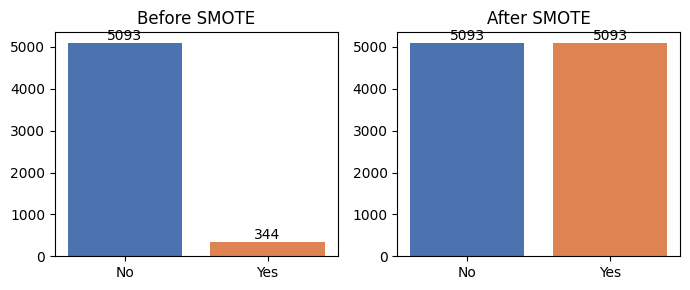

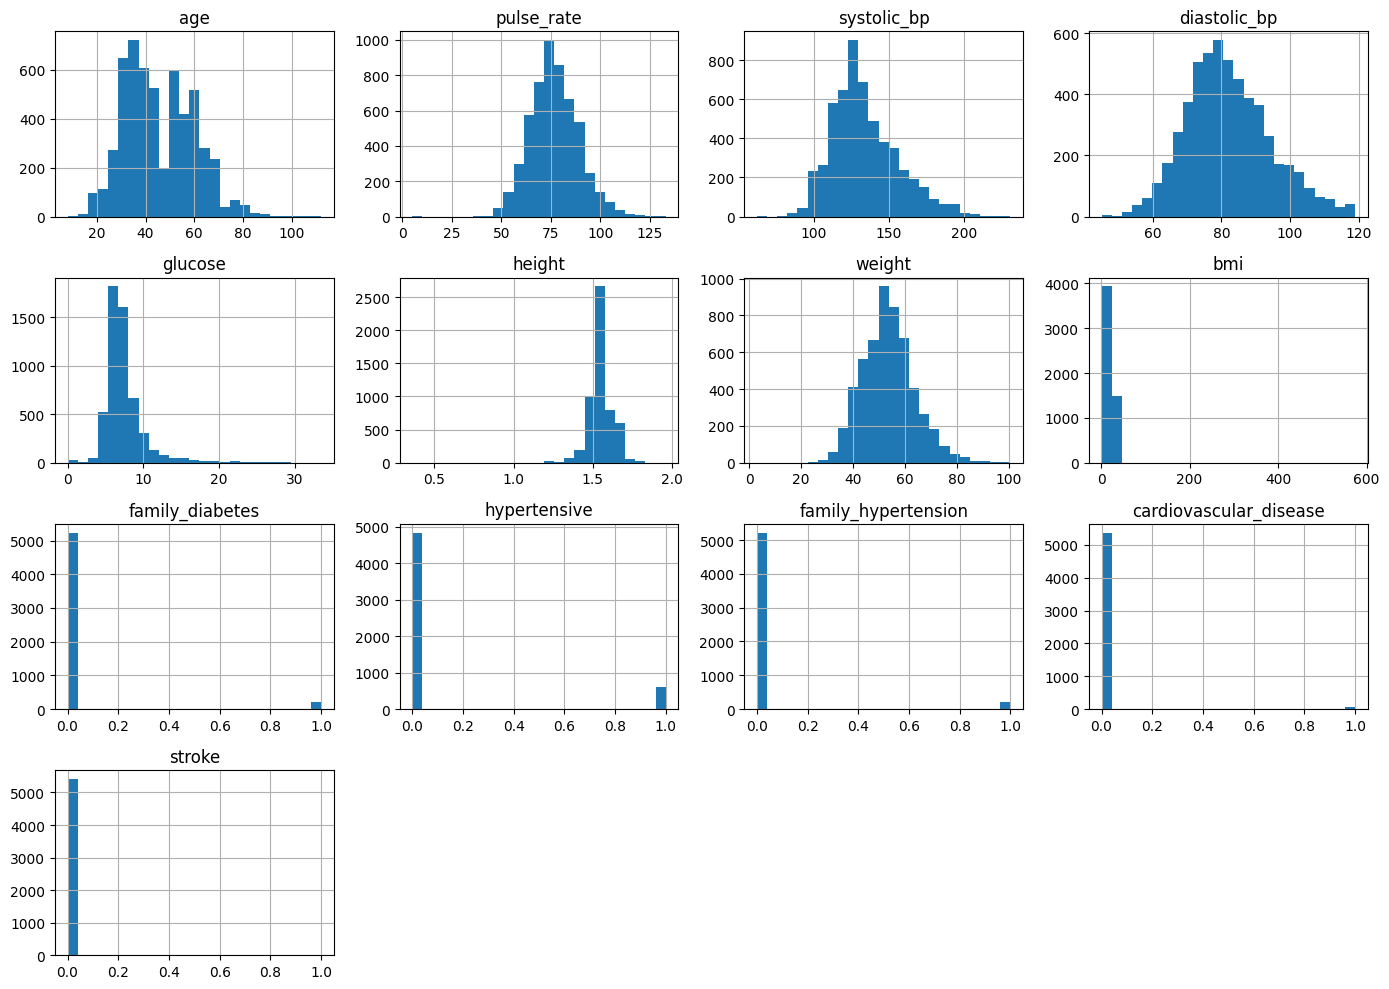

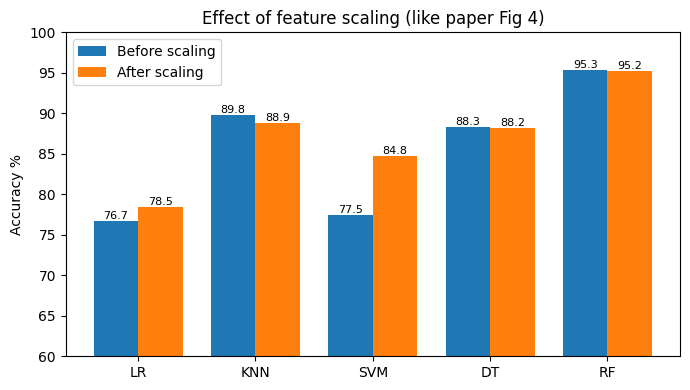

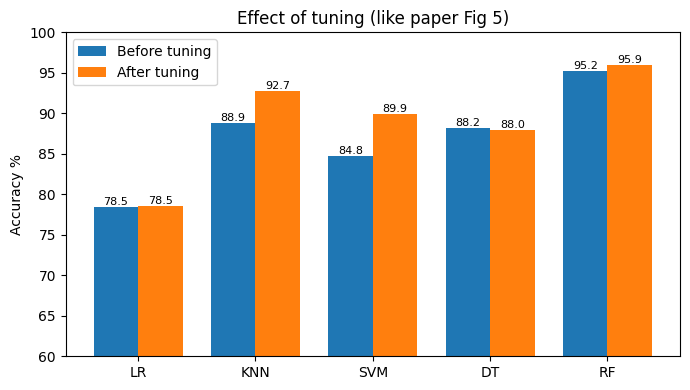

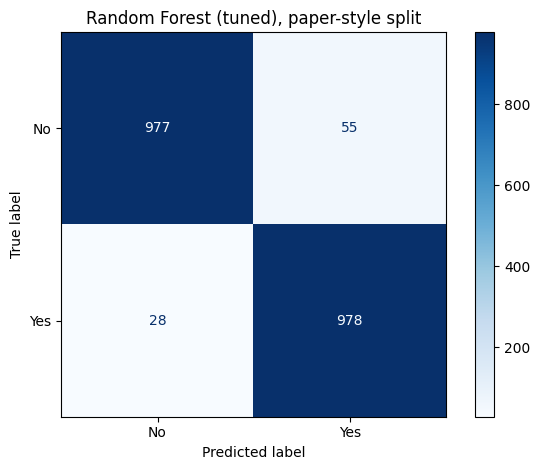

Saved model.pkl for the Streamlit app


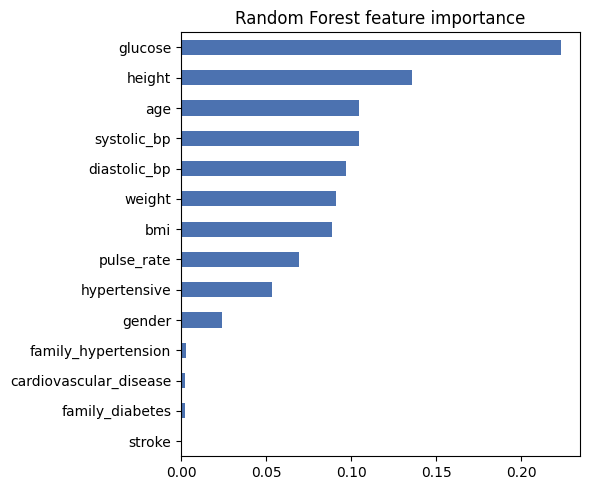

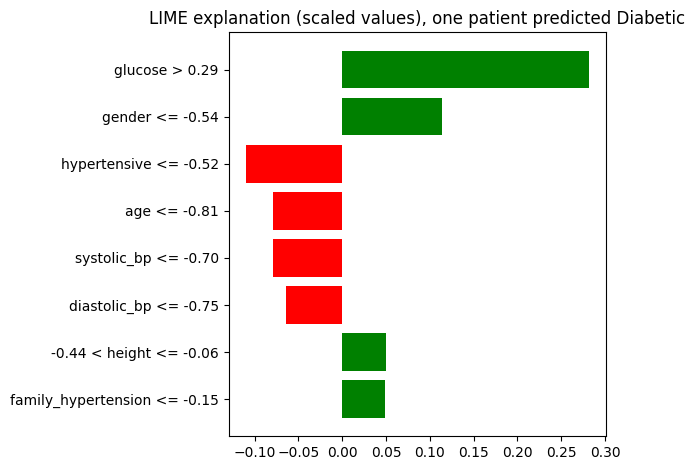

LIME probabilities [No, Yes]: [0. 1.]
Same patient, real values:
age                        36.00
gender                      0.00
pulse_rate                 79.00
systolic_bp               115.00
diastolic_bp               76.00
glucose                    13.71
height                      1.54
weight                     69.01
bmi                        29.22
family_diabetes             0.00
hypertensive                0.00
family_hypertension         0.00
cardiovascular_disease      0.00
stroke                      0.00


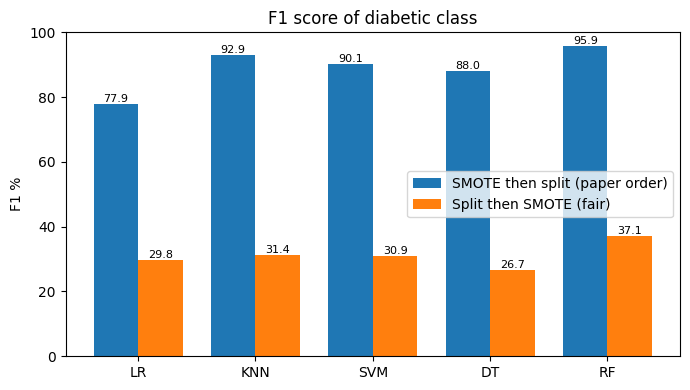


All figures saved in the folder: figures

Run finished without error: 2026-11-24 17:44:36 (Pakistan time)


In [ ]:
# CS877 project - Phase 2: plots, feature importance and LIME (paper Figures 2, 4, 5, 6)
# Colab: first cell ->  !pip install lime imbalanced-learn
# Then upload Diabetes_Final_Data_V2.csv and run this file in one cell.

import datetime
from zoneinfo import ZoneInfo
_now = lambda: datetime.datetime.now(ZoneInfo("Asia/Karachi")).strftime("%Y-%m-%d %H:%M:%S (Pakistan time)")
print("Run started:", _now())
import os, sys, subprocess, warnings; warnings.filterwarnings("ignore")
for pkg, mod in [("lime", "lime"), ("imbalanced-learn", "imblearn")]:
    try:
        __import__(mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE
from lime.lime_tabular import LimeTabularExplainer

CSV_PATH = "Diabetes_Final_Data_V2.csv"
OUT = "figures"; os.makedirs(OUT, exist_ok=True)
def save(name):
    plt.tight_layout(); plt.savefig(f"{OUT}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

df = pd.read_csv(CSV_PATH)
y = (df["diabetic"] == "Yes").astype(int)
X = df.drop(columns=["diabetic"]).copy()
X["gender"] = (X["gender"] == "Male").astype(int)
names = list(X.columns)

print("=== Paper Figure 3: data frame information ===")
df.info()

# ---- Fig A: class balance before and after SMOTE ----
Xs, ys = SMOTE(random_state=42).fit_resample(X, y)
fig, ax = plt.subplots(1, 2, figsize=(7, 3))
for a_, lab, s in zip(ax, ["Before SMOTE", "After SMOTE"], [y, ys]):
    cnt = s.value_counts().sort_index(); a_.bar(["No", "Yes"], cnt.values, color=["#4c72b0", "#dd8452"])
    a_.set_title(lab); [a_.text(i, v, str(v), ha="center", va="bottom") for i, v in enumerate(cnt.values)]
save("A_class_balance")

# ---- Fig B: histograms of all 13 numeric columns (paper Figure 2) ----
df.drop(columns=["gender", "diabetic"]).hist(bins=25, figsize=(14, 10))
save("B_histograms_paper_fig2")

# ---- Models: paper-style split (SMOTE first, then 80:20) ----
a, b, c, d = train_test_split(Xs, ys, test_size=0.2, random_state=42)
sc = StandardScaler().fit(a); a_s, b_s = sc.transform(a), sc.transform(b)
mk = lambda: {"LR": LogisticRegression(), "KNN": KNeighborsClassifier(), "SVM": SVC(),
              "DT": DecisionTreeClassifier(random_state=42), "RF": RandomForestClassifier(random_state=42)}
TUNED = {"LR": LogisticRegression(C=0.01, penalty="l2", solver="liblinear"),
         "KNN": KNeighborsClassifier(metric="euclidean", n_neighbors=2, weights="uniform"),
         "SVM": SVC(C=100, gamma="auto", kernel="rbf"),
         "DT": DecisionTreeClassifier(criterion="entropy", max_depth=13, random_state=42),
         "RF": RandomForestClassifier(bootstrap=False, max_depth=20, n_estimators=200, random_state=42)}
acc = lambda ms, A, B: {n: accuracy_score(d, m.fit(A, c).predict(B)) * 100 for n, m in ms.items()}
r_no, r_sc, r_tu = acc(mk(), a, b), acc(mk(), a_s, b_s), acc(TUNED, a_s, b_s)

def grouped(r1, r2, l1, l2, title, name, lo=60, ylabel="Accuracy %"):
    x = np.arange(5); w = 0.38; ks = list(r1)
    plt.figure(figsize=(7, 4))
    p1 = plt.bar(x - w/2, [r1[k] for k in ks], w, label=l1); p2 = plt.bar(x + w/2, [r2[k] for k in ks], w, label=l2)
    plt.bar_label(p1, fmt="%.1f", fontsize=8); plt.bar_label(p2, fmt="%.1f", fontsize=8)
    plt.xticks(x, ks); plt.ylim(lo, 100); plt.ylabel(ylabel); plt.title(title); plt.legend()
    save(name)
grouped(r_no, r_sc, "Before scaling", "After scaling", "Effect of feature scaling (like paper Fig 4)", "C_scaling")
grouped(r_sc, r_tu, "Before tuning", "After tuning", "Effect of tuning (like paper Fig 5)", "D_tuning")

# ---- Confusion matrix and feature importance of the best model (Random Forest) ----
rf = TUNED["RF"].fit(a_s, c)
ConfusionMatrixDisplay.from_predictions(d, rf.predict(b_s), display_labels=["No", "Yes"], cmap="Blues")
plt.title("Random Forest (tuned), paper-style split"); save("E_confusion_matrix")

import pickle
pickle.dump({"model": rf, "scaler": sc, "features": names,
             "importance": dict(zip(names, rf.feature_importances_))}, open("model.pkl", "wb"))
print("Saved model.pkl for the Streamlit app")
imp = pd.Series(rf.feature_importances_, index=names).sort_values()
plt.figure(figsize=(6, 5)); imp.plot.barh(color="#4c72b0"); plt.title("Random Forest feature importance")
save("F_feature_importance")

# ---- Fig 6 style: LIME explanation for one patient ----
explainer = LimeTabularExplainer(a_s, feature_names=names, class_names=["No", "Yes"], mode="classification", random_state=42)
pos = np.where(rf.predict(b_s) == 1)[0][0]          # first test patient predicted diabetic
exp = explainer.explain_instance(b_s[pos], rf.predict_proba, num_features=8)
exp.as_pyplot_figure(); plt.title("LIME explanation (scaled values), one patient predicted Diabetic"); save("G_lime")
print("LIME probabilities [No, Yes]:", rf.predict_proba(b_s[pos:pos+1])[0].round(2))
print("Same patient, real values:"); print(pd.Series(sc.inverse_transform(b_s[pos:pos+1])[0], index=names).round(2).add(0.0).to_string())

# ---- Extra for Part E: paper-style vs no-leakage test, F1 score ----
a2, b2, c2, d2 = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
a2, c2 = SMOTE(random_state=42).fit_resample(a2, c2)
sc2 = StandardScaler().fit(a2)
f_leak = {n: f1_score(d, m.fit(a_s, c).predict(b_s)) * 100 for n, m in TUNED.items()}
f_fair = {n: f1_score(d2, m.fit(sc2.transform(a2), c2).predict(sc2.transform(b2))) * 100 for n, m in TUNED.items()}
grouped(f_leak, f_fair, "SMOTE then split (paper order)", "Split then SMOTE (fair)", "F1 score of diabetic class", "H_leakage_check", lo=0, ylabel="F1 %")
print("\nAll figures saved in the folder:", OUT)

print("\nRun finished without error:", _now())


## Step 4: novelty
1. **Fair evaluation:** SMOTE only on the training data.
2. **Method change:** choose the decision threshold on training data instead of using 0.5.
3. **Stress test:** noisy and missing measurements.

Cross-validation is only the measuring tool. It is not the novelty.

Run started: 2026-11-24 17:44:37 (Pakistan time)

PART 1 - 5-fold results on REAL patients only (%):
                  Setup  precision    recall        F1    PR-AUC   ROC-AUC
       RF, no balancing  77.3+-8.4 20.1+-5.1 31.2+-5.7 44.6+-1.4 87.6+-1.7
      RF, class weights 73.6+-10.0 18.3+-3.7 28.9+-4.1 43.2+-1.3 87.3+-1.2
RF, SMOTE on train only  32.0+-1.7 43.6+-3.2 36.8+-1.6 35.4+-1.7 85.2+-1.1
LR, SMOTE on train only  23.2+-0.8 73.8+-3.2 35.3+-0.7 41.3+-3.5 86.3+-1.7
Paper-order reference (SMOTE before split): RF F1 about 96 %

PART 2 - decision threshold (threshold chosen inside the training part only, so it is fair):
RF, threshold 0.5      precision 72.2  recall 18.3  F1 28.8+-4.1   (mean threshold 0.50)
RF, tuned threshold    precision 38.5  recall 44.2  F1 40.3+-1.5   (mean threshold 0.22)

PART 3 - F1 (%) of the tuned-threshold RF when test measurements are corrupted:
noise       0: 40.3   0.1: 39.4  0.25: 39.9   0.5: 37.2   1.0: 37.7
missing     0: 40.3   0.1: 39.3   0.2: 35.

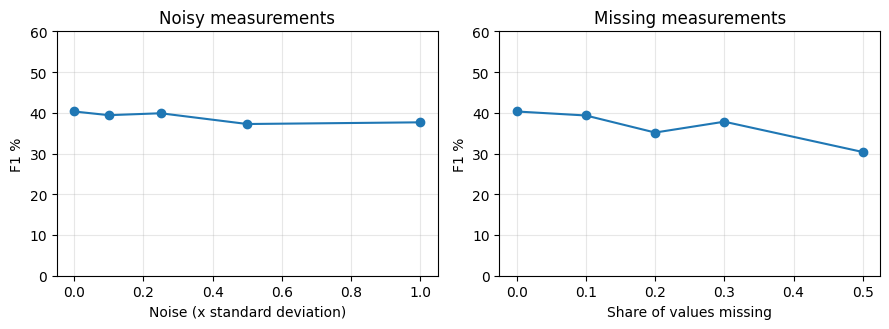


Run finished without error: 2026-11-24 17:45:14 (Pakistan time)


In [ ]:
# CS877 project - NOVELTY (3 parts). Colab: one cell. Takes about 3-6 minutes.
# Part 1  Evaluation   : is the paper's high score still true on real patients only? (SMOTE only on training data)
# Part 2  Method change: choose the decision threshold on training data (cost-sensitive), instead of the default 0.5
# Part 3  Robustness   : what happens to the F1 score when test measurements are noisy or missing?
# Cross-validation is only the measuring tool here. It is NOT the novelty.

import datetime
from zoneinfo import ZoneInfo
_now = lambda: datetime.datetime.now(ZoneInfo("Asia/Karachi")).strftime("%Y-%m-%d %H:%M:%S (Pakistan time)")
print("Run started:", _now())
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve, f1_score, recall_score, precision_score
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

df = pd.read_csv("Diabetes_Final_Data_V2.csv")
y = (df["diabetic"] == "Yes").astype(int).values
X = df.drop(columns=["diabetic"]).copy(); X["gender"] = (X["gender"] == "Male").astype(int)
cols = list(X.columns); Xv = X.values.astype(float)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
RF = dict(n_estimators=200, max_depth=20, random_state=42, n_jobs=-1)   # paper's tuned RF
mk_rf = lambda: RandomForestClassifier(class_weight="balanced_subsample", **RF)

# ---------------- Part 1: evaluation without leakage ----------------
scoring = ["precision", "recall", "f1", "average_precision", "roc_auc"]
setups = {
 "RF, no balancing":            RandomForestClassifier(**RF),
 "RF, class weights":           mk_rf(),
 "RF, SMOTE on train only":     Pipeline([("sm", SMOTE(random_state=42)), ("m", RandomForestClassifier(**RF))]),
 "LR, SMOTE on train only":     Pipeline([("sc", StandardScaler()), ("sm", SMOTE(random_state=42)), ("m", LogisticRegression(C=0.01, solver="liblinear"))]),
}
rows = []
for n, m in setups.items():
    r = cross_validate(m, X, y, cv=cv, scoring=scoring)
    rows.append({"Setup": n, **{k: f"{r['test_'+k].mean()*100:.1f}+-{r['test_'+k].std()*100:.1f}" for k in scoring}})
print("\nPART 1 - 5-fold results on REAL patients only (%):")
print(pd.DataFrame(rows).rename(columns={"average_precision": "PR-AUC", "roc_auc": "ROC-AUC", "f1": "F1"}).to_string(index=False))
print("Paper-order reference (SMOTE before split): RF F1 about 96 %")

# ---------------- Part 2: method change = threshold chosen on training data ----------------
def best_threshold(model, Xtr, ytr):
    p = cross_val_predict(model, Xtr, ytr, cv=StratifiedKFold(3, shuffle=True, random_state=1), method="predict_proba")[:, 1]
    pr, rc, th = precision_recall_curve(ytr, p); f1 = 2 * pr * rc / (pr + rc + 1e-9)
    return th[f1[:-1].argmax()]

store = []   # keep fitted models for part 3
res = {"RF, threshold 0.5": [], "RF, tuned threshold": []}
for tr, te in cv.split(Xv, y):
    m = mk_rf().fit(Xv[tr], y[tr]); th = best_threshold(mk_rf(), Xv[tr], y[tr])
    pr = m.predict_proba(Xv[te])[:, 1]
    for k, t in [("RF, threshold 0.5", 0.5), ("RF, tuned threshold", th)]:
        p = (pr >= t).astype(int)
        res[k].append([precision_score(y[te], p), recall_score(y[te], p), f1_score(y[te], p), t])
    store.append((tr, te, m, th))
print("\nPART 2 - decision threshold (threshold chosen inside the training part only, so it is fair):")
for k, v in res.items():
    v = np.array(v) * 100; print(f"{k:22} precision {v[:,0].mean():.1f}  recall {v[:,1].mean():.1f}  F1 {v[:,2].mean():.1f}+-{v[:,2].std():.1f}   (mean threshold {v[:,3].mean()/100:.2f})")

# ---------------- Part 3: robustness to noisy / missing measurements ----------------
meas = [cols.index(c) for c in ["pulse_rate", "systolic_bp", "diastolic_bp", "glucose"]]
rng = np.random.default_rng(0)
def corrupt(Xte, Xtr, kind, level):
    Z = Xte.copy()
    if level == 0: return Z
    for j in meas:
        if kind == "noise":
            Z[:, j] += rng.normal(0, level * Xtr[:, j].std(), len(Z))
        else:
            Z[rng.random(len(Z)) < level, j] = np.nan
            Z[np.isnan(Z[:, j]), j] = np.median(Xtr[:, j])   # fill with the training median
    return Z
levels = {"noise": [0, 0.1, 0.25, 0.5, 1.0], "missing": [0, 0.1, 0.2, 0.3, 0.5]}
out = {}
for kind, lv in levels.items():
    for L in lv:
        f = []
        for tr, te, m, th in store:
            Z = corrupt(Xv[te], Xv[tr], kind, L)
            f.append(f1_score(y[te], (m.predict_proba(Z)[:, 1] >= th).astype(int)) * 100)
        out[(kind, L)] = np.mean(f)
print("\nPART 3 - F1 (%) of the tuned-threshold RF when test measurements are corrupted:")
for kind, lv in levels.items():
    print(f"{kind:8}", "  ".join(f"{L:>4}: {out[(kind, L)]:.1f}" for L in lv))
print("(noise level = size of noise as a fraction of each measurement's standard deviation; missing level = share of values removed)")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for a_, kind, xl in zip(ax, levels, ["Noise (x standard deviation)", "Share of values missing"]):
    a_.plot(levels[kind], [out[(kind, L)] for L in levels[kind]], "o-"); a_.set_xlabel(xl); a_.set_ylabel("F1 %"); a_.set_ylim(0, 60); a_.grid(alpha=.3)
ax[0].set_title("Noisy measurements"); ax[1].set_title("Missing measurements")
plt.tight_layout(); plt.savefig("novelty_robustness.png", dpi=150); plt.show()

print("\nRun finished without error:", _now())


## Step 5: numbers for Deliverable 2 and the viva
Headline gap, 15-seed variation, one-at-a-time sensitivity, and removing one component. Takes 5 to 8 minutes. **Save this output as your log** (File > Download .ipynb) and screenshot the top and bottom lines for the date and time.

In [ ]:
# CS877 Deliverable 2 - numbers for the slides and the viva questions
# Headline result being reproduced: tuned Random Forest accuracy (paper Table 5 and abstract: 94.80 %, "95 %")
# Parts: A headline gap | B seed variation | C hyperparameter sensitivity | D ablation (remove one component)
# Colab: run in one cell. About 5-8 minutes. Save the notebook output as your log.

import sys, datetime, warnings; warnings.filterwarnings("ignore")
from zoneinfo import ZoneInfo
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score
from imblearn.over_sampling import SMOTE

PARTS = sys.argv[1] if len(sys.argv) > 1 and sys.argv[1] in "ABCD" else "ABCD"
now = lambda: datetime.datetime.now(ZoneInfo("Asia/Karachi")).strftime("%Y-%m-%d %H:%M:%S (Pakistan time)")
print("Run started:", now())

df = pd.read_csv("Diabetes_Final_Data_V2.csv")
y = (df["diabetic"] == "Yes").astype(int)
X = df.drop(columns=["diabetic"]).copy(); X["gender"] = (X["gender"] == "Male").astype(int)
PAPER_RF_TUNED = 94.80   # paper Table 5, Random Forest accuracy %
TUNED = dict(bootstrap=False, max_depth=20, min_samples_leaf=1, min_samples_split=2, n_estimators=200)   # paper Table 4

def paper_order(seed=42, scale=True, **rf_kw):
    """Paper's order: SMOTE on all data, then 80:20 split (then scale)."""
    Xs, ys = SMOTE(random_state=seed).fit_resample(X, y)
    a, b, c, d = train_test_split(Xs, ys, test_size=0.2, random_state=seed)
    if scale:
        s = StandardScaler().fit(a); a, b = s.transform(a), s.transform(b)
    p = RandomForestClassifier(random_state=seed, **rf_kw).fit(a, c).predict(b)
    return accuracy_score(d, p) * 100, f1_score(d, p) * 100

def fair(seed=42, **rf_kw):
    """Fair order: split first, SMOTE on the training part only. Test = real patients."""
    a, b, c, d = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    a, c = SMOTE(random_state=seed).fit_resample(a, c)
    s = StandardScaler().fit(a)
    p = RandomForestClassifier(random_state=seed, **rf_kw).fit(s.transform(a), c).predict(s.transform(b))
    return accuracy_score(d, p) * 100, f1_score(d, p) * 100

mine, _ = paper_order(42, **TUNED)
if "A" in PARTS:
    gap = mine - PAPER_RF_TUNED
    print("\n=== A. Headline result: tuned Random Forest accuracy ===")
    print(f"Paper (Table 5): {PAPER_RF_TUNED:.2f} %   Mine (seed 42): {mine:.2f} %")
    print(f"Gap: {gap:+.2f} percentage points absolute, {gap / PAPER_RF_TUNED * 100:+.2f} % relative")

if "B" in PARTS:
    print("\n=== B. Is the gap larger than the variation across random seeds? (15 seeds) ===")
    seeds = range(15); po = np.array([paper_order(s, **TUNED) for s in seeds]); fr = np.array([fair(s, **TUNED) for s in seeds])
    m, sd = po[:, 0].mean(), po[:, 0].std()
    print(f"Paper-order accuracy: mean {m:.2f}, std {sd:.2f}, min {po[:,0].min():.2f}, max {po[:,0].max():.2f}")
    print(f"Paper value {PAPER_RF_TUNED:.2f} is {(m - PAPER_RF_TUNED) / sd:.1f} standard deviations below my mean")
    print("Gap larger than seed variation:", "YES" if abs(m - PAPER_RF_TUNED) > 2 * sd else "NO")
    print(f"Paper-order F1:  mean {po[:,1].mean():.1f}, std {po[:,1].std():.1f}")
    print(f"Fair-order accuracy: mean {fr[:,0].mean():.1f}, std {fr[:,0].std():.1f}")
    print(f"Fair-order F1:   mean {fr[:,1].mean():.1f}, std {fr[:,1].std():.1f}")

if "C" in PARTS:
    print("\n=== C. Sensitivity: change ONE Random Forest setting at a time (seed 42, paper-order accuracy %) ===")
    grid = {"n_estimators": [10, 50, 100, 200, 500], "max_depth": [3, 5, 10, 20, None],
            "min_samples_leaf": [1, 2, 5, 10], "bootstrap": [True, False]}
    spread = {}
    for k, vals in grid.items():
        accs = []
        for v in vals:
            kw = dict(TUNED); kw[k] = v; accs.append(paper_order(42, **kw)[0])
        spread[k] = max(accs) - min(accs)
        print(f"{k:17}", "  ".join(f"{v}: {a:.2f}" for v, a in zip(vals, accs)), f"  -> range {spread[k]:.2f}")
    print("Most sensitive setting:", max(spread, key=spread.get))
    print(f"For comparison: changing the EVALUATION ORDER (SMOTE before vs after split) changes accuracy by "
          f"{mine - fair(42, **TUNED)[0]:.1f} points and F1 by {paper_order(42, **TUNED)[1] - fair(42, **TUNED)[1]:.1f} points")

if "D" in PARTS:
    print("\n=== D. Ablation: remove one component of the pipeline (tuned RF, seed 42) ===")
    f_acc, f_f1 = paper_order(42, **TUNED)
    print(f"{'Setup':38} {'Acc %':>7} {'F1 %':>7}")
    print(f"{'Full pipeline (paper order)':38} {f_acc:7.2f} {f_f1:7.2f}")
    a_, f_ = paper_order(42, scale=False, **TUNED); print(f"{'Remove scaling':38} {a_:7.2f} {f_:7.2f}")
    a_, f_ = paper_order(42, scale=True, n_estimators=100); print(f"{'Remove tuning (default RF)':38} {a_:7.2f} {f_:7.2f}")
    a1, b1, c1, d1 = train_test_split(X, y, test_size=0.2, random_state=42)
    s = StandardScaler().fit(a1)
    p = RandomForestClassifier(random_state=42, **TUNED).fit(s.transform(a1), c1).predict(s.transform(b1))
    print(f"{'Remove SMOTE (real test patients)':38} {accuracy_score(d1,p)*100:7.2f} {f1_score(d1,p)*100:7.2f}   recall {recall_score(d1,p)*100:.1f} %")
    a_, f_ = fair(42, **TUNED); print(f"{'Move SMOTE after split (real test)':38} {a_:7.2f} {f_:7.2f}")

print("\nRun finished without error:", now())


Run started: 2026-11-24 17:45:14 (Pakistan time)

=== A. Headline result: tuned Random Forest accuracy ===
Paper (Table 5): 94.80 %   Mine (seed 42): 95.93 %
Gap: +1.13 percentage points absolute, +1.19 % relative

=== B. Is the gap larger than the variation across random seeds? (15 seeds) ===
Paper-order accuracy: mean 95.42, std 0.45, min 94.21, max 96.07
Paper value 94.80 is 1.4 standard deviations below my mean
Gap larger than seed variation: NO
Paper-order F1:  mean 95.5, std 0.5
Fair-order accuracy: mean 91.2, std 0.9
Fair-order F1:   mean 36.1, std 4.6

=== C. Sensitivity: change ONE Random Forest setting at a time (seed 42, paper-order accuracy %) ===
n_estimators      10: 94.50  50: 95.29  100: 95.73  200: 95.93  500: 95.88   -> range 1.42
max_depth         3: 80.57  5: 82.88  10: 90.68  20: 95.93  None: 95.68   -> range 15.36
min_samples_leaf  1: 95.93  2: 95.53  5: 93.87  10: 91.81   -> range 4.12
bootstrap         True: 95.09  False: 95.93   -> range 0.83
Most sensitive set

## Step 6 (optional): Streamlit app files
The app cannot be shown inside Colab. Download `app.py` and `model.pkl`, put them in one folder on your laptop, and run `pip install streamlit scikit-learn pandas` and then `streamlit run app.py`. Use the same scikit-learn version on both sides, or run Step 3 on your laptop too.

In [ ]:
%%writefile app.py
# CS877 project - Streamlit app (paper Figures 7-9)
# Run on your laptop:  pip install streamlit scikit-learn pandas
#                      streamlit run app.py
# model.pkl must be in the same folder (reproduce_figures.py creates it).

import pickle
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Diabetes Risk Prediction", page_icon="🩺")
bundle = pickle.load(open("model.pkl", "rb"))
model, scaler, features, importance = bundle["model"], bundle["scaler"], bundle["features"], bundle["importance"]

st.title("Diabetes Risk Prediction")
st.write("Random Forest model trained on the DiaHealth dataset (5,437 patients, Bangladesh).")
st.caption("Research prototype for a university course. Not a medical tool. It does not replace a doctor.")

yn = {"No": 0, "Yes": 1}
c1, c2 = st.columns(2)
with c1:
    age = st.number_input("Age (years)", 1, 120, 45)
    gender = st.selectbox("Gender", ["Female", "Male"])
    pulse = st.number_input("Pulse rate (beats/min)", 30, 200, 76)
    sys_bp = st.number_input("Systolic BP (mmHg)", 60, 260, 130)
    dia_bp = st.number_input("Diastolic BP (mmHg)", 40, 150, 80)
    glucose = st.number_input("Glucose (mmol/L)", 2.0, 40.0, 6.9, step=0.1)
    height = st.number_input("Height (m)", 1.0, 2.2, 1.55, step=0.01)
with c2:
    weight = st.number_input("Weight (kg)", 20.0, 200.0, 53.0, step=0.5)
    fam_dia = st.selectbox("Family history of diabetes", list(yn))
    hyper = st.selectbox("Hypertensive", list(yn))
    fam_hyp = st.selectbox("Family history of hypertension", list(yn))
    cvd = st.selectbox("Cardiovascular disease", list(yn))
    stroke = st.selectbox("Stroke", list(yn))

if st.button("Predict"):
    bmi = weight / (height ** 2)
    row = {"age": age, "gender": int(gender == "Male"), "pulse_rate": pulse, "systolic_bp": sys_bp,
           "diastolic_bp": dia_bp, "glucose": glucose, "height": height, "weight": weight, "bmi": bmi,
           "family_diabetes": yn[fam_dia], "hypertensive": yn[hyper], "family_hypertension": yn[fam_hyp],
           "cardiovascular_disease": yn[cvd], "stroke": yn[stroke]}
    X = scaler.transform(pd.DataFrame([row])[features])
    prob = model.predict_proba(X)[0][1]
    if model.predict(X)[0] == 1:
        st.error(f"Diabetes detected (model probability {prob:.0%})")
    else:
        st.success(f"No diabetes detected (model probability of diabetes {prob:.0%})")
    st.write(f"BMI used by the model: {bmi:.1f}")
    st.subheader("Top factors the model uses overall")
    top = pd.Series(importance).sort_values(ascending=False).head(5)
    st.table(top.rename("importance").round(3))


Writing app.py


In [ ]:
try:
    from google.colab import files
    files.download("app.py"); files.download("model.pkl")
except ImportError:
    print("Not in Colab: app.py and model.pkl are in the current folder")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>